# Soft Computing for Biometric Authentication: Implementation


In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from skimage.feature import hog

SEEDS = [0, 1, 2, 3, 4]          # five different random train/test splits
plt.rcParams['figure.dpi'] = 110

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to C:\Users\srira\scikit_learn_data
Images: 400  |  Size: 64x64  |  People: 40


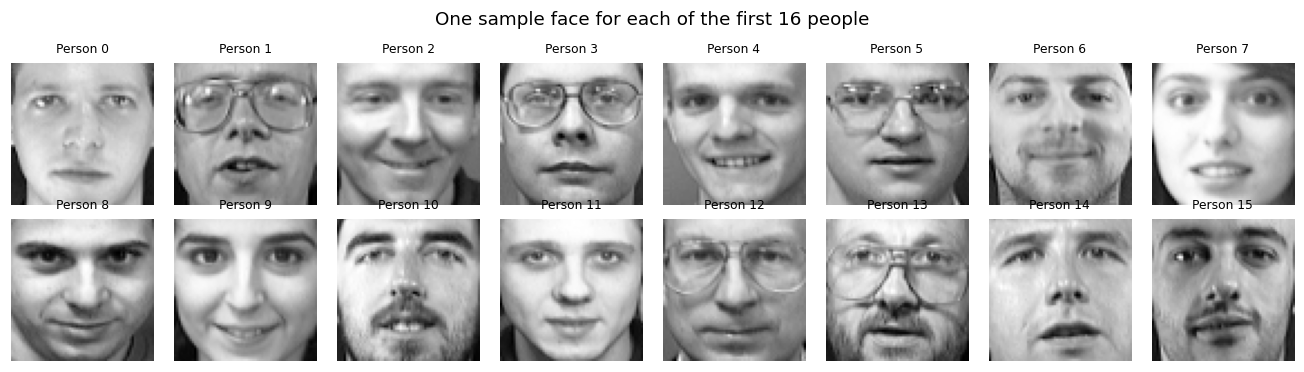

In [2]:
faces = fetch_olivetti_faces()            # downloads about 1.5 MB the first time
images, labels = faces.images, faces.target
X = images.reshape(len(images), -1)       # each face becomes a 4,096-long vector
N_PEOPLE = len(np.unique(labels))
print(f'Images: {images.shape[0]}  |  Size: {images.shape[1]}x{images.shape[2]}  |  People: {N_PEOPLE}')

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, person in zip(axes.ravel(), range(16)):
    ax.imshow(images[person * 10], cmap='gray'); ax.set_title(f'Person {person}', fontsize=8); ax.axis('off')
plt.suptitle('One sample face for each of the first 16 people'); plt.tight_layout(); plt.show()

In [3]:
def split(seed):
    '''7 training and 3 test images per person.'''
    return train_test_split(np.arange(len(X)), test_size=0.3, stratify=labels, random_state=seed)

tr, te = split(0)
print('Training images:', len(tr), '| Test images:', len(te))

Training images: 280 | Test images: 120


---
# Part A: Swarm and evolutionary feature selection

**Pipeline:** face image → PCA eigenface features (100 numbers per face) → feature selection (none / PSO / GA) → nearest-neighbour matcher (1-NN) → identity.

PCA (principal component analysis) turns each face into 100 *eigenface* coefficients. Some of them describe identity, others mostly describe lighting or expression. A good subset should therefore recognise people at least as well as all 100.

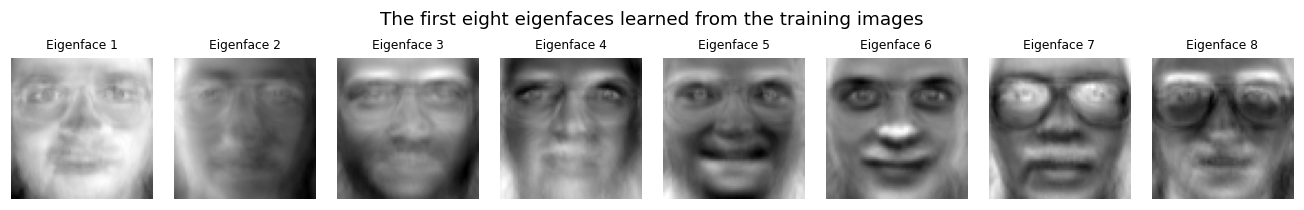

100 components keep 94.6% of the image variance


In [4]:
N_COMPONENTS = 100

def eigenface_features(train_idx):
    '''Fit PCA on the training faces only, then describe all 400 faces with 100 eigenface coefficients.'''
    pca = PCA(n_components=N_COMPONENTS, random_state=0).fit(X[train_idx])
    return pca, pca.transform(X)

pca, F = eigenface_features(tr)
fig, axes = plt.subplots(1, 8, figsize=(12, 1.9))
for i, ax in enumerate(axes):
    ax.imshow(pca.components_[i].reshape(64, 64), cmap='gray'); ax.set_title(f'Eigenface {i+1}', fontsize=8); ax.axis('off')
plt.suptitle('The first eight eigenfaces learned from the training images'); plt.tight_layout(); plt.show()
print(f'100 components keep {pca.explained_variance_ratio_.sum()*100:.1f}% of the image variance')

### A.1 Fitness function

A feature subset is a **binary mask** of length 100 (1 = use the feature). Its fitness is the **leave-one-out 1-NN accuracy on the training images only**: each training face is matched to its nearest other training face using just the selected features. The swarm and the genetic algorithm try to maximise this number.

In [5]:
def sq_dist(A, B):
    '''Squared Euclidean distance between every row of A and every row of B.'''
    return ((A[:, None, :] - B[None, :, :]) ** 2).sum(-1)

def fitness(mask, F, tr):
    '''Leave-one-out nearest-neighbour accuracy on the training images, using only the selected features.'''
    if not mask.any():
        return 0.0
    Z = F[tr][:, mask]
    d = sq_dist(Z, Z)
    np.fill_diagonal(d, np.inf)                      # a face may not match itself
    return (labels[tr][d.argmin(1)] == labels[tr]).mean()

def test_accuracy(mask, F, tr, te):
    '''Identify every test face by its nearest training face (rank-1 identification accuracy).'''
    d = sq_dist(F[te][:, mask], F[tr][:, mask])
    return (labels[tr][d.argmin(1)] == labels[te]).mean()

ALL = np.ones(N_COMPONENTS, dtype=bool)
print(f'All 100 features: training fitness = {fitness(ALL, F, tr):.3f}, test accuracy = {test_accuracy(ALL, F, tr, te):.3f}')

All 100 features: training fitness = 0.896, test accuracy = 0.900


### A.2 Binary Particle Swarm Optimisation (PSO)

Each particle is a candidate feature mask. Every iteration, a particle's velocity is pulled towards its own best mask (*pbest*) and the swarm's best mask (*gbest*):

$v \leftarrow w\,v + c_1 r_1 (pbest - x) + c_2 r_2 (gbest - x)$

A sigmoid of the velocity gives the probability that each bit is 1. Settings: 20 particles, 40 iterations, $w = 0.7$, $c_1 = c_2 = 1.5$.

In [6]:
def binary_pso(F, tr, n_particles=20, n_iter=40, w=0.7, c1=1.5, c2=1.5, seed=0):
    rng = np.random.default_rng(seed)
    D = F.shape[1]
    pos = rng.random((n_particles, D)) < 0.5                     # random starting masks
    vel = rng.uniform(-1, 1, (n_particles, D))
    pbest = pos.copy()
    pbest_fit = np.array([fitness(p, F, tr) for p in pos])
    gbest, gbest_fit = pbest[pbest_fit.argmax()].copy(), pbest_fit.max()
    history = [gbest_fit]
    for _ in range(n_iter):
        r1, r2 = rng.random((n_particles, D)), rng.random((n_particles, D))
        vel = w * vel + c1 * r1 * (pbest - pos.astype(float)) + c2 * r2 * (gbest - pos.astype(float))
        vel = np.clip(vel, -4, 4)
        pos = rng.random((n_particles, D)) < 1 / (1 + np.exp(-vel))   # sigmoid transfer function
        fit = np.array([fitness(p, F, tr) for p in pos])
        better = fit > pbest_fit
        pbest[better], pbest_fit[better] = pos[better], fit[better]
        if pbest_fit.max() > gbest_fit:
            gbest, gbest_fit = pbest[pbest_fit.argmax()].copy(), pbest_fit.max()
        history.append(gbest_fit)
    return gbest, history

### A.3 Genetic Algorithm (GA)

The evolutionary baseline uses the operators the paper names: **selection** (tournament of two), **crossover** (uniform, probability 0.9) and **mutation** (bit flip, probability 0.02 per bit), plus **elitism** (the best mask always survives). Settings: population 20, 40 generations, so it gets the same number of fitness evaluations as PSO.

In [7]:
def genetic_algorithm(F, tr, pop_size=20, n_gen=40, p_cross=0.9, p_mut=0.02, seed=0):
    rng = np.random.default_rng(seed)
    D = F.shape[1]
    pop = rng.random((pop_size, D)) < 0.5
    fit = np.array([fitness(p, F, tr) for p in pop])
    best, best_fit = pop[fit.argmax()].copy(), fit.max()
    history = [best_fit]
    for _ in range(n_gen):
        a, b = rng.integers(pop_size, size=(2, pop_size))             # tournament selection
        parents = pop[np.where(fit[a] >= fit[b], a, b)]
        children = parents.copy()
        for i in range(0, pop_size - 1, 2):                            # uniform crossover
            if rng.random() < p_cross:
                swap = rng.random(D) < 0.5
                children[i, swap], children[i + 1, swap] = parents[i + 1, swap], parents[i, swap]
        children ^= rng.random((pop_size, D)) < p_mut                  # bit-flip mutation
        children[0] = best                                             # elitism
        pop = children
        fit = np.array([fitness(p, F, tr) for p in pop])
        if fit.max() > best_fit:
            best, best_fit = pop[fit.argmax()].copy(), fit.max()
        history.append(best_fit)
    return best, history

### A.4 One run, step by step (split 0)

Search time: 12.0 s

Method         Features  Train fitness  Test accuracy
All features        100          0.896          0.900
PSO                  52          0.925          0.908
GA                   51          0.950          0.900


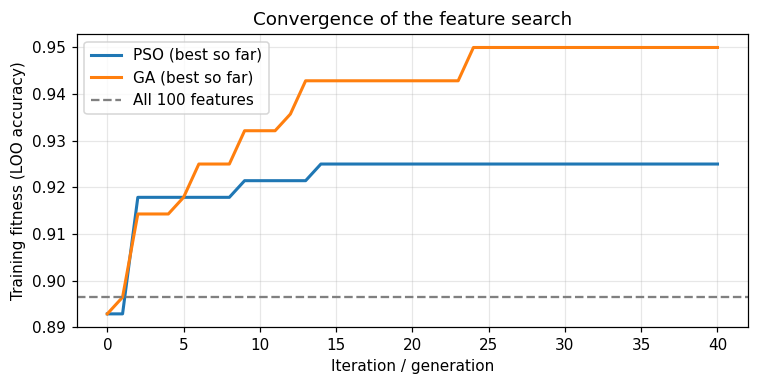

In [8]:
t0 = time.time()
pso_mask, pso_hist = binary_pso(F, tr, seed=0)
ga_mask, ga_hist = genetic_algorithm(F, tr, seed=0)
print(f'Search time: {time.time() - t0:.1f} s\n')

print(f"{'Method':<14}{'Features':>9}{'Train fitness':>15}{'Test accuracy':>15}")
for name, m in [('All features', ALL), ('PSO', pso_mask), ('GA', ga_mask)]:
    print(f'{name:<14}{m.sum():>9}{fitness(m, F, tr):>15.3f}{test_accuracy(m, F, tr, te):>15.3f}')

plt.figure(figsize=(7, 3.6))
plt.plot(pso_hist, label='PSO (best so far)', lw=2)
plt.plot(ga_hist, label='GA (best so far)', lw=2)
plt.axhline(fitness(ALL, F, tr), color='grey', ls='--', label='All 100 features')
plt.xlabel('Iteration / generation'); plt.ylabel('Training fitness (LOO accuracy)')
plt.title('Convergence of the feature search'); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### A.5 Repeat on five random splits

Split    All (%)  PSO (%)   GA (%)  PSO feats  GA feats
0           90.0     90.8     90.0         52        51
1           93.3     94.2     95.8         55        57
2           94.2     93.3     94.2         58        58
3           90.8     92.5     93.3         54        60
4           95.8     95.8     95.8         53        47
Mean        92.8     93.3     93.8         54        55
Std          2.1      1.7      2.1

Average gain over all features: PSO +0.5 points, GA +1.0 points (paper: +3 to +8 points for PSO)
Features kept: PSO about 54 of 100, GA about 55 of 100


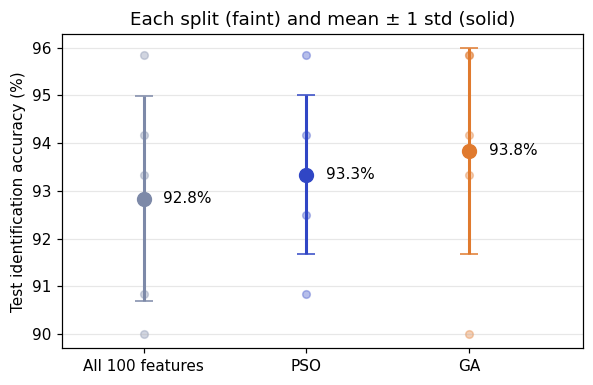

In [9]:
rows = []
for s in SEEDS:
    tr_s, te_s = split(s)
    _, F_s = eigenface_features(tr_s)
    pm, _ = binary_pso(F_s, tr_s, seed=s)
    gm, _ = genetic_algorithm(F_s, tr_s, seed=s)
    rows.append([test_accuracy(ALL, F_s, tr_s, te_s), test_accuracy(pm, F_s, tr_s, te_s),
                 test_accuracy(gm, F_s, tr_s, te_s), pm.sum(), gm.sum()])
R = np.array(rows)
R[:, :3] *= 100

print(f"{'Split':<7}{'All (%)':>9}{'PSO (%)':>9}{'GA (%)':>9}{'PSO feats':>11}{'GA feats':>10}")
for s, r in zip(SEEDS, R):
    print(f'{s:<7}{r[0]:>9.1f}{r[1]:>9.1f}{r[2]:>9.1f}{int(r[3]):>11}{int(r[4]):>10}')
mean, std = R.mean(0), R.std(0)
print(f"{'Mean':<7}{mean[0]:>9.1f}{mean[1]:>9.1f}{mean[2]:>9.1f}{mean[3]:>11.0f}{mean[4]:>10.0f}")
print(f"{'Std':<7}{std[0]:>9.1f}{std[1]:>9.1f}{std[2]:>9.1f}")
pso_gain, ga_gain = mean[1] - mean[0], mean[2] - mean[0]
print(f'\nAverage gain over all features: PSO {pso_gain:+.1f} points, GA {ga_gain:+.1f} points (paper: +3 to +8 points for PSO)')
print(f'Features kept: PSO about {mean[3]:.0f} of 100, GA about {mean[4]:.0f} of 100')

plt.figure(figsize=(5.5, 3.6))
labels_a = ['All 100 features', 'PSO', 'GA']
for i, (lab, col) in enumerate(zip(labels_a, ['#7d89a8', '#3046c5', '#e07a2e'])):
    plt.scatter([i] * len(SEEDS), R[:, i], color=col, alpha=.35, s=25)          # each split
    plt.errorbar(i, mean[i], yerr=std[i], fmt='o', color=col, ms=9, capsize=6, lw=2)  # mean +/- std
    plt.text(i + 0.12, mean[i], f'{mean[i]:.1f}%', va='center')
plt.xticks(range(3), labels_a); plt.xlim(-0.5, 2.7)
plt.ylabel('Test identification accuracy (%)')
plt.title('Each split (faint) and mean ± 1 std (solid)'); plt.grid(axis='y', alpha=.3); plt.tight_layout(); plt.show()

---
# Part B: Fuzzy score-level fusion (verification)

Now the task is **verification**: *is this face the person it claims to be?* Each test face is compared with every person's **template** (the average of their 7 training images), which gives 1 genuine comparison and 39 impostor comparisons per face (120 genuine and 4,680 impostor scores per split).

Two matchers look at the face in different ways, making a **multi-algorithm** biometric system (one of the six multibiometric types in the paper):

1. **Eigenface matcher:** cosine similarity of PCA features (global appearance).
2. **HOG matcher:** cosine similarity of Histogram of Oriented Gradients features (local edges and shape).

Their scores are fused at **score level** in two ways: the simple mean (sum rule) and a **fuzzy inference system**.

In [10]:
def hog_features(imgs):
    return np.array([hog(im, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2)) for im in imgs])

H = hog_features(images)
print('HOG feature length per face:', H.shape[1])

def match_scores(F, tr, probes):
    '''Cosine similarity between each probe face and every person's template (mean of their training faces).
    When the probe is itself a training face, it is left out of its own template (leave-one-out).'''
    sums = np.zeros((N_PEOPLE, F.shape[1])); counts = np.zeros(N_PEOPLE)
    for i in tr:
        sums[labels[i]] += F[i]; counts[labels[i]] += 1
    tr_set = set(tr.tolist())
    S = np.zeros((len(probes), N_PEOPLE))
    for j, i in enumerate(probes):
        T, n = sums.copy(), counts.copy()
        if i in tr_set:
            T[labels[i]] -= F[i]; n[labels[i]] -= 1
        T /= n[:, None]
        S[j] = (T @ F[i]) / (np.linalg.norm(T, axis=1) * np.linalg.norm(F[i]))
    return S

HOG feature length per face: 1764


### B.1 Error rates: FAR, FRR and EER

- **FAR** (False Acceptance Rate): share of impostor comparisons wrongly accepted.
- **FRR** (False Rejection Rate): share of genuine comparisons wrongly rejected.
- **EER** (Equal Error Rate): the threshold where FAR = FRR. Lower is better.

In [11]:
def far_frr(S, true_labels, thresholds):
    idx = np.arange(len(true_labels))
    genuine = S[idx, true_labels]
    impostor_mask = np.ones_like(S, dtype=bool); impostor_mask[idx, true_labels] = False
    impostor = S[impostor_mask]
    far = np.array([(impostor >= t).mean() for t in thresholds]) * 100
    frr = np.array([(genuine < t).mean() for t in thresholds]) * 100
    return far, frr

def eer(S, true_labels):
    th = np.linspace(S.min(), S.max(), 1000)
    far, frr = far_frr(S, true_labels, th)
    i = np.argmin(np.abs(far - frr))
    return (far[i] + frr[i]) / 2, th[i]

### B.2 The fuzzy fusion system

Each matcher's score is first scaled to 0–1 using the minimum and maximum of the **training** scores. Each scaled score is then described by three fuzzy sets, *low*, *medium* and *high*. Nine IF–THEN rules combine them, for example:

- IF eigenface score is **high** AND HOG score is **high** THEN match = 1.0
- IF one score is **high** AND the other is **medium** THEN match = 0.75
- IF one score is **high** AND the other is **low** THEN match = 0.5 (the matchers disagree)

This is a zero-order **Sugeno** fuzzy system: AND = minimum, and the output is the rule strengths' weighted average. Unlike the plain mean, it can treat agreement and disagreement between the matchers differently.

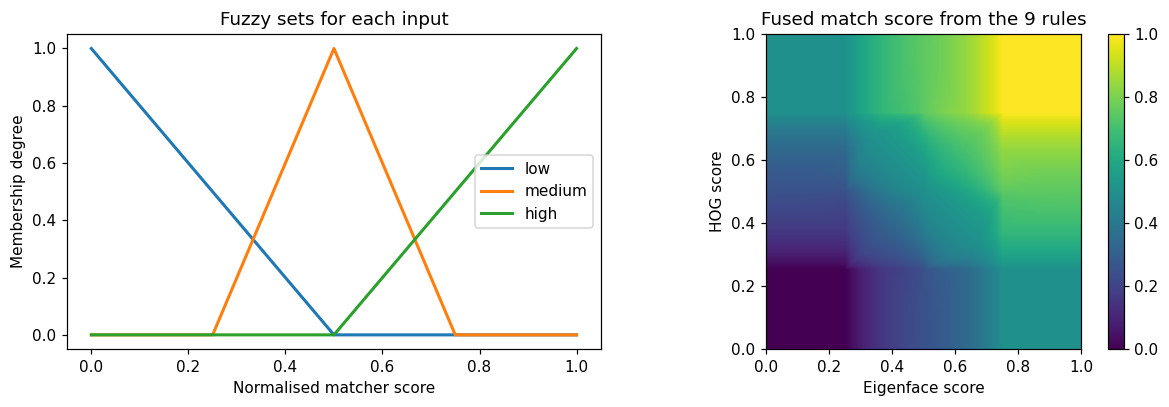

In [12]:
def normalise(S_train, S):
    '''Min-max scaling using training scores only, clipped to [0, 1].'''
    lo, hi = S_train.min(), S_train.max()
    return np.clip((S - lo) / (hi - lo), 0, 1)

def memberships(x):
    low = np.clip((0.5 - x) / 0.5, 0, 1)
    medium = np.clip(np.minimum((x - 0.25) / 0.25, (0.75 - x) / 0.25), 0, 1)
    high = np.clip((x - 0.5) / 0.5, 0, 1)
    return {'low': low, 'medium': medium, 'high': high}

RULES = {('low', 'low'): 0.0,  ('low', 'medium'): 0.25,  ('medium', 'low'): 0.25,
         ('low', 'high'): 0.5, ('high', 'low'): 0.5,     ('medium', 'medium'): 0.5,
         ('medium', 'high'): 0.75, ('high', 'medium'): 0.75, ('high', 'high'): 1.0}

def fuzzy_fusion(a, b):
    ma, mb = memberships(a), memberships(b)
    num, den = np.zeros_like(a), np.zeros_like(a)
    for (fa, fb), out in RULES.items():
        w = np.minimum(ma[fa], mb[fb])        # rule firing strength (AND = min)
        num += w * out; den += w
    return num / np.maximum(den, 1e-9)       # weighted-average defuzzification

grid = np.linspace(0, 1, 201)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for name, mu in memberships(grid).items():
    ax1.plot(grid, mu, lw=2, label=name)
ax1.set_xlabel('Normalised matcher score'); ax1.set_ylabel('Membership degree'); ax1.set_title('Fuzzy sets for each input'); ax1.legend()
A, B = np.meshgrid(grid, grid)
im = ax2.imshow(fuzzy_fusion(A, B), origin='lower', extent=[0, 1, 0, 1], cmap='viridis')
ax2.set_xlabel('Eigenface score'); ax2.set_ylabel('HOG score'); ax2.set_title('Fused match score from the 9 rules')
plt.colorbar(im, ax=ax2); plt.tight_layout(); plt.show()

### B.3 One run, step by step (split 0)

Eigenface only   EER =  9.81%
HOG only         EER =  7.50%
Mean fusion      EER =  5.81%
Fuzzy fusion     EER =  5.83%


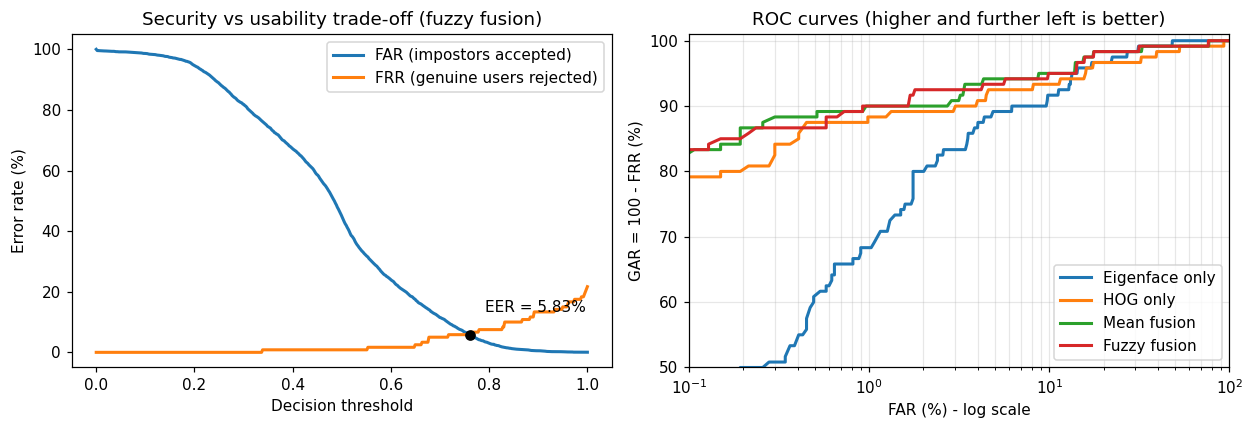

In [13]:
def fusion_experiment(seed):
    tr_s, te_s = split(seed)
    _, F_s = eigenface_features(tr_s)
    scores = {}
    train_scores = {}
    for name, feats in [('Eigenface', F_s), ('HOG', H)]:
        train_scores[name] = match_scores(feats, tr_s, tr_s)
        scores[name] = match_scores(feats, tr_s, te_s)
    a = normalise(train_scores['Eigenface'], scores['Eigenface'])
    b = normalise(train_scores['HOG'], scores['HOG'])
    systems = {'Eigenface only': a, 'HOG only': b, 'Mean fusion': (a + b) / 2, 'Fuzzy fusion': fuzzy_fusion(a, b)}
    return systems, labels[te_s]

systems, y_te = fusion_experiment(0)
for name, S in systems.items():
    e, _ = eer(S, y_te)
    print(f'{name:<16} EER = {e:5.2f}%')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4))
th = np.linspace(0, 1, 500)
far, frr = far_frr(systems['Fuzzy fusion'], y_te, th)
e, t_eer = eer(systems['Fuzzy fusion'], y_te)
ax1.plot(th, far, lw=2, label='FAR (impostors accepted)')
ax1.plot(th, frr, lw=2, label='FRR (genuine users rejected)')
ax1.scatter([t_eer], [e], color='k', zorder=3); ax1.annotate(f'EER = {e:.2f}%', (t_eer, e), xytext=(10, 15), textcoords='offset points')
ax1.set_xlabel('Decision threshold'); ax1.set_ylabel('Error rate (%)'); ax1.set_title('Security vs usability trade-off (fuzzy fusion)'); ax1.legend()
for name, S in systems.items():
    th_s = np.linspace(S.min(), S.max(), 1000)
    far_s, frr_s = far_frr(S, y_te, th_s)
    ax2.plot(far_s, 100 - frr_s, lw=2, label=name)
ax2.set_xscale('log'); ax2.set_xlim(0.1, 100); ax2.set_ylim(50, 101)
ax2.set_xlabel('FAR (%) - log scale'); ax2.set_ylabel('GAR = 100 - FRR (%)'); ax2.set_title('ROC curves (higher and further left is better)')
ax2.legend(loc='lower right'); ax2.grid(alpha=.3, which='both'); plt.tight_layout(); plt.show()

### B.4 Repeat on five random splits

Split    Eigenface only        HOG only     Mean fusion    Fuzzy fusion
0                 9.81%           7.50%           5.81%           5.83%
1                 7.44%           6.72%           5.84%           5.01%
2                 7.48%           7.47%           4.29%           4.16%
3                 9.19%           9.13%           5.83%           6.66%
4                 8.33%           5.24%           4.16%           5.00%
Mean              8.45%           7.21%           5.19%           5.33%
Std               0.94%           1.26%           0.79%           0.85%

Fuzzy fusion lowers the mean EER from 7.21% (best single matcher) to 5.33%; mean fusion reaches 5.19%.
Fuzzy fusion beats mean fusion on 2 of 5 splits.


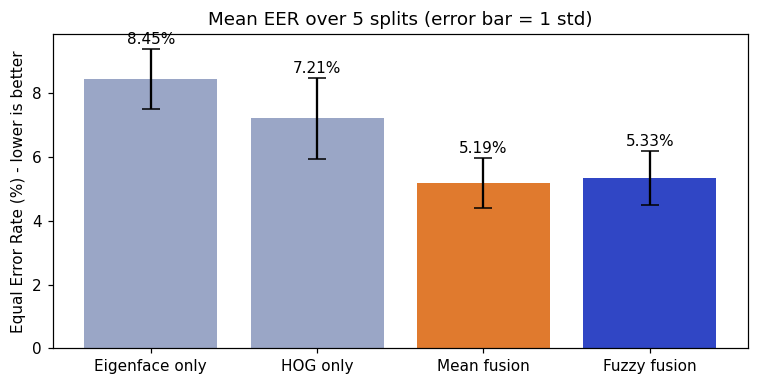

In [14]:
names = ['Eigenface only', 'HOG only', 'Mean fusion', 'Fuzzy fusion']
E = []
for s in SEEDS:
    systems_s, y_s = fusion_experiment(s)
    E.append([eer(systems_s[n], y_s)[0] for n in names])
E = np.array(E)

print(f"{'Split':<7}" + ''.join(f'{n:>16}' for n in names))
for s, row in zip(SEEDS, E):
    print(f'{s:<7}' + ''.join(f'{v:>15.2f}%' for v in row))
print(f"{'Mean':<7}" + ''.join(f'{v:>15.2f}%' for v in E.mean(0)))
print(f"{'Std':<7}" + ''.join(f'{v:>15.2f}%' for v in E.std(0)))
best_single = E[:, :2].mean(0).min()
print(f'\nFuzzy fusion lowers the mean EER from {best_single:.2f}% (best single matcher) to {E[:, 3].mean():.2f}%;'
      f' mean fusion reaches {E[:, 2].mean():.2f}%.')
print(f'Fuzzy fusion beats mean fusion on {(E[:, 3] < E[:, 2]).sum()} of {len(SEEDS)} splits.')

plt.figure(figsize=(7, 3.6))
plt.bar(names, E.mean(0), yerr=E.std(0), capsize=6, color=['#9aa6c6', '#9aa6c6', '#e07a2e', '#3046c5'])
for i, v in enumerate(E.mean(0)):
    plt.text(i, v + E.std(0)[i] + 0.15, f'{v:.2f}%', ha='center')
plt.ylabel('Equal Error Rate (%) - lower is better'); plt.title('Mean EER over 5 splits (error bar = 1 std)')
plt.tight_layout(); plt.show()

---
# Summary

In [15]:
print('PART A - feature selection (rank-1 identification, mean of 5 splits)')
print(f'  All 100 eigenface features : {mean[0]:.1f}%')
print(f'  PSO-selected features      : {mean[1]:.1f}%  ({pso_gain:+.1f} points, about {mean[3]:.0f} features)')
print(f'  GA-selected features       : {mean[2]:.1f}%  ({ga_gain:+.1f} points, about {mean[4]:.0f} features)')
print('  Paper claims PSO gains of 3-8 points over full-feature baselines.\n')
print('PART B - verification EER (mean of 5 splits, lower is better)')
for n, v in zip(names, E.mean(0)):
    print(f'  {n:<16}: {v:.2f}%')

PART A - feature selection (rank-1 identification, mean of 5 splits)
  All 100 eigenface features : 92.8%
  PSO-selected features      : 93.3%  (+0.5 points, about 54 features)
  GA-selected features       : 93.8%  (+1.0 points, about 55 features)
  Paper claims PSO gains of 3-8 points over full-feature baselines.

PART B - verification EER (mean of 5 splits, lower is better)
  Eigenface only  : 8.45%
  HOG only        : 7.21%
  Mean fusion     : 5.19%
  Fuzzy fusion    : 5.33%
